# 01 - Clip LAS to raster tiles (Site 1)

This notebook mirrors the `clipping_toRaster_onefile.py` and `clipping_toRaster_daskMultiples.py` workflow using the packaged `rasterclip` functions.

- Pre-crops in LAS/native CRS using raster bounds transformed to LAS CRS
- Reprojects output to raster CRS
# --- Overlay: Raster 5/3/1 + LAS ---

In [17]:
# RGB point clouds 
from pathlib import Path

# --- CONFIGURATION: Site 1 (DD0001) ---
SITE_NAME = 'site1_DD0001'

# Input LAS (coreg)
INPUT_RGB_LAS = Path("/data/calperumResearch/site1_1_DD0001/imagery/SASMDD0001_rgb_pc.las")

# Raster tiles directory and pattern
AOI_RASTER_DIR = Path('/data/calperumResearch/site1_1_DD0001/imagery/inputs/predictors/tiles_3072/stacked/')
RASTER_PATTERN = 'tiles_multispectral*.tif'

# Single tile example
TILE_ID = '109'
A_TILE = AOI_RASTER_DIR / f'tiles_multispectral.{TILE_ID}.tif'

# Output directory
OUT_DIR = Path("/data/calperumResearch/site1_1_DD0001/imagery/clipped/raster")
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('--- Configuration ---')
print(f'Raster dir  : {AOI_RASTER_DIR}')
print(f'LAS dir     : {INPUT_RGB_LAS}')
print(f'Pattern     : {RASTER_PATTERN}')
print(f'Single tile : {TILE_ID}')
print(f'Output dir  : {OUT_DIR}')
print('----------------------')

--- Configuration ---
Raster dir  : /data/calperumResearch/site1_1_DD0001/imagery/inputs/predictors/tiles_3072/stacked
LAS dir     : /data/calperumResearch/site1_1_DD0001/imagery/SASMDD0001_rgb_pc.las
Pattern     : tiles_multispectral*.tif
Single tile : 109
Output dir  : /data/calperumResearch/site1_1_DD0001/imagery/clipped/raster
----------------------


In [30]:
# Coregistered LiDAR point clouds
from pathlib import Path

# --- CONFIGURATION: Site 1 (DD0001) ---
SITE_NAME = 'site1_DD0001'

# Input LAS (coreg)
INPUT_LAS = Path('/data/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las')

# Raster tiles directory and pattern
AOI_RASTER_DIR = Path('/data/calperumResearch/site1_1_DD0001/imagery/inputs/predictors/tiles_3072/stacked/')
RASTER_PATTERN = 'tiles_multispectral*.tif'

# Single tile example
TILE_ID = '109'
A_TILE = AOI_RASTER_DIR / f'tiles_multispectral.{TILE_ID}.tif'

# Output directory
OUT_DIR = Path('/data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg')
OUT_DIR.mkdir(parents=True, exist_ok=True)

print('--- Configuration ---')
print(f'Raster dir  : {AOI_RASTER_DIR}')
print(f'LAS dir     : {INPUT_LAS}')
print(f'Pattern     : {RASTER_PATTERN}')
print(f'Single tile : {TILE_ID}')
print(f'Output dir  : {OUT_DIR}')
print('----------------------')

--- Configuration ---
Raster dir  : /data/calperumResearch/site1_1_DD0001/imagery/inputs/predictors/tiles_3072/stacked
LAS dir     : /data/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
Pattern     : tiles_multispectral*.tif
Single tile : 109
Output dir  : /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg
----------------------


In [2]:
# --- Single tile clip (optional; can be slow) ---
import time
from rasterclip import clip_single

out_single = OUT_DIR / f'{A_TILE.stem}.las'
print('Starting single-tile clip...')
t0 = time.time()
pts = clip_single(INPUT_LAS, A_TILE, out_single)
dt = time.time() - t0
print(f'✅ Single tile written: {out_single} ({pts} points) in {dt:.2f}s')
print('Tip: If single-tile is slow, run Dask batch directly for better throughput.')

Starting single-tile clip...
✅ Single tile written: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/tiles_multispectral.109.las (1593892 points) in 86.67s
Tip: If single-tile is slow, run Dask batch directly for better throughput.


In [10]:
# --- Batch clip: sequential and Dask with signature ---
from rasterclip import clip_many, clip_many_dask
from pathlib import Path

# Sequential
outs_seq = clip_many(INPUT_LAS, AOI_RASTER_DIR, OUT_DIR, pattern=RASTER_PATTERN, skip_existing=True)
print(f'✅ Sequential batch outputs: {len(outs_seq)}')

# Dask-parallel with signature logging
outs_dask = clip_many_dask(
    INPUT_LAS,
    AOI_RASTER_DIR,
    OUT_DIR,
    pattern=RASTER_PATTERN,
    skip_existing=True,
    write_signature=True,
)
print(f'✅ Dask batch outputs: {len(outs_dask)}')

sig_path = OUT_DIR / 'clip_signature.txt'
if sig_path.exists():
    print(f'📝 Signature file: {sig_path}')
    try:
        print(sig_path.read_text())
    except Exception:
        print('Signature written, but could not display contents.')

✅ Sequential batch outputs: 0
Dask dashboard: http://172.16.1.208:8787/status
Dask dashboard: http://172.16.1.208:8787/status


Clipping LAS to tiles: 0it [00:00, ?it/s]

Signature written: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/clip_signature.txt
✅ Done clipping. Successful: 0, Failed: 0, Elapsed: 0.55s
✅ Dask batch outputs: 15
📝 Signature file: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/clip_signature.txt
Date: 2025-12-15 04:02:32
Input LAS: /data/calperumResearch/site1_1_DD0001/lidar/20220519_SASMDD0001_triple_AusGeoid_coreg.las
AOI dir: /data/calperumResearch/site1_1_DD0001/imagery/inputs/predictors/tiles_3072/stacked
Pattern: tiles_multispectral*.tif
Output dir: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg
Total rasters: 15
Successful tiles: 0
Skipped tiles: 0
Failed tiles: 0
Total points processed: 0
Elapsed time (s): 0.55



In [11]:
# --- Inspect one output LAS ---
import laspy, numpy as np

sample_out = out_single if out_single.exists() else (OUT_DIR / f'tiles_multispectral.{TILE_ID}.las')
print(f'Inspecting: {sample_out}')
las = laspy.read(sample_out)
print(f'Total points: {len(las.points):,}')
print('Bounding box:')
print(f'  X: {las.header.mins[0]:.2f} → {las.header.maxs[0]:.2f}')
print(f'  Y: {las.header.mins[1]:.2f} → {las.header.maxs[1]:.2f}')
print(f'  Z: {las.header.mins[2]:.2f} → {las.header.maxs[2]:.2f}')
print(f'Point format: {las.header.point_format}')
print(f'Extra dims : {[dim.name for dim in las.point_format.extra_dimensions]}')

Inspecting: /data/calperumResearch/site1_1_DD0001/lidar/clipped/raster/coreg/tiles_multispectral.109.las
Total points: 1,593,979
Bounding box:
  X: 461771.54 → 461802.23
  Y: 6237506.15 → 6237536.84
  Z: 55.40 → 61.04
Point format: <PointFormat(7, 0 bytes of extra dims)>
Extra dims : []


In [5]:
# Tip: Dask dashboard
print('If running Dask in this notebook, check the dashboard in logs or via Client().dashboard_link')

If running Dask in this notebook, check the dashboard in logs or via Client().dashboard_link


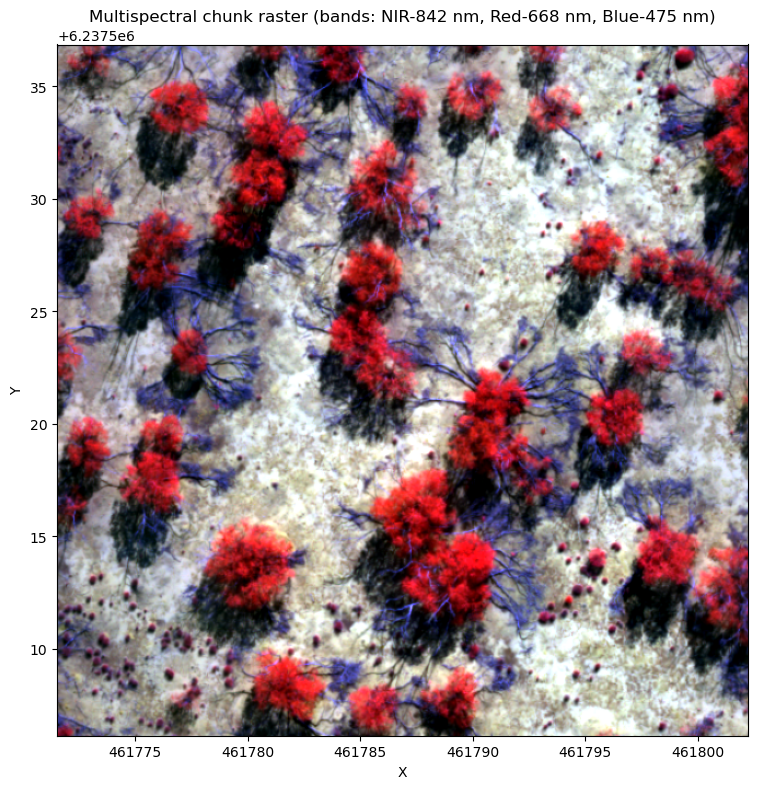

In [26]:
# --- View original raster (bands 5/3/1) ---
import rasterio, numpy as np, matplotlib.pyplot as plt

tile_path = A_TILE
with rasterio.open(tile_path) as src:
    if src.count < 5:
        raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
    b5 = src.read(5).astype(np.float32)
    b3 = src.read(3).astype(np.float32)
    b1 = src.read(1).astype(np.float32)
    def norm_band(b):
        lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
        b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
        b[~np.isfinite(b)] = 0
        return b
    rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

plt.figure(figsize=(8, 8))
plt.imshow(rgb, extent=extent, origin='upper')
plt.title('Multispectral chunk raster (bands: NIR-842 nm, Red-668 nm, Blue-475 nm)')
plt.xlabel('X'); plt.ylabel('Y')
plt.tight_layout(); plt.show()

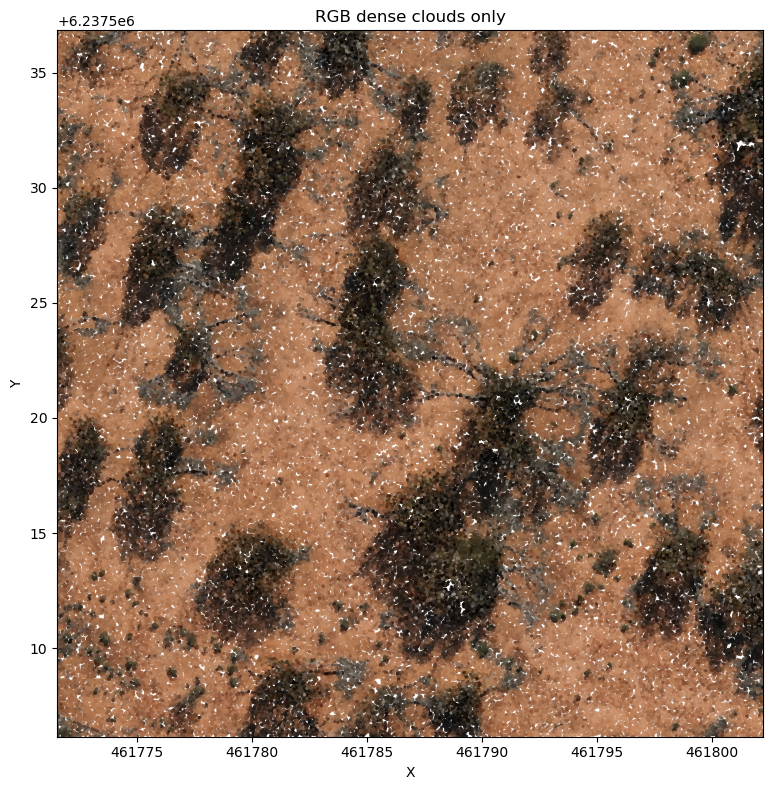

In [27]:
# --- View RGB dense clouds only (coloured by RGB if available; else by Z) ---
import laspy, numpy as np, matplotlib.pyplot as plt
import rasterio

# Get extent from raster
with rasterio.open(A_TILE) as src:
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

las_path = OUT_DIR / f"{A_TILE.stem}.las"
if not las_path.exists():
    las_path = sample_out
las = laspy.read(las_path)

x = las.x
y = las.y
use_rgb = hasattr(las, 'red') and hasattr(las, 'green') and hasattr(las, 'blue')
if use_rgb:
    r = np.asarray(las.red, dtype=np.float32)
    g = np.asarray(las.green, dtype=np.float32)
    b = np.asarray(las.blue, dtype=np.float32)
    colors = np.stack([r, g, b], axis=-1) / 65535.0
else:
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    colors = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

n = len(x); max_pts = 200000
if n > max_pts:
    idx = np.random.choice(n, size=max_pts, replace=False)
    x = x[idx]; y = y[idx]
    colors = colors[idx]

plt.figure(figsize=(8, 8))
plt.title('RGB dense clouds only')
plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
if use_rgb:
    plt.scatter(x, y, s=2, c=colors, alpha=0.8)
else:
    plt.scatter(x, y, s=2, c=colors, cmap='viridis', alpha=0.8)
plt.tight_layout(); plt.show()

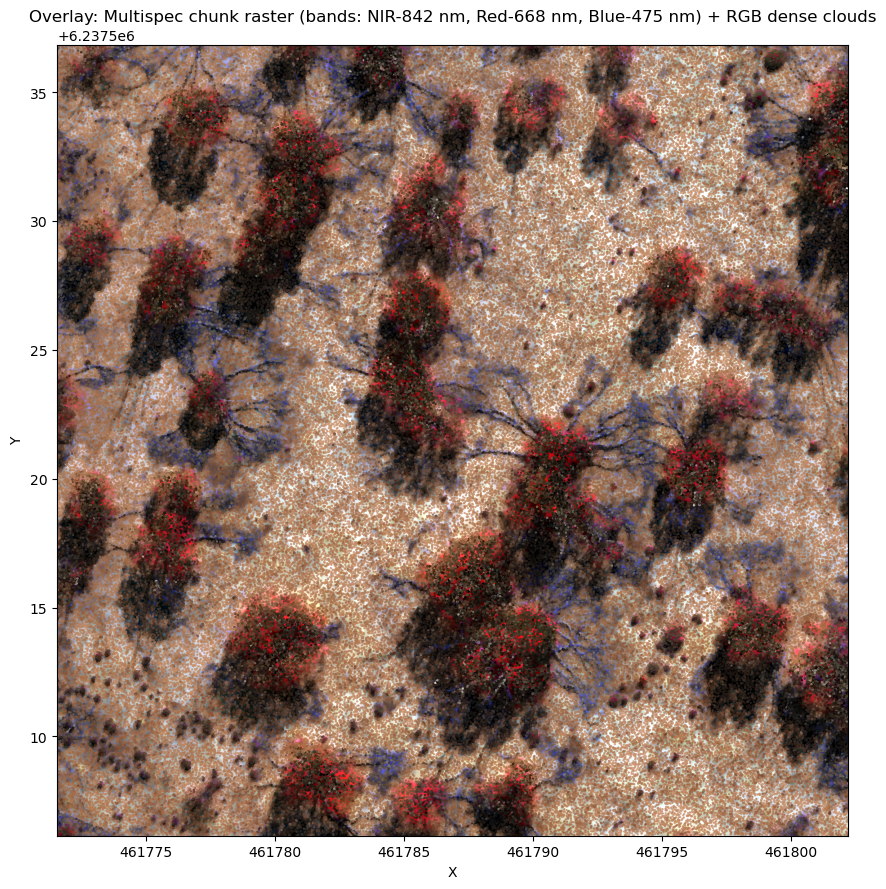

In [28]:
# --- Overlay: Raster 5/3/1 + LAS ---
import matplotlib.pyplot as plt
import rasterio

# Get extent from raster if not already in scope
try:
    extent
    rgb
except NameError:
    import numpy as np
    with rasterio.open(A_TILE) as src:
        if src.count < 5:
            raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
        b5 = src.read(5).astype(np.float32)
        b3 = src.read(3).astype(np.float32)
        b1 = src.read(1).astype(np.float32)
        def norm_band(b):
            lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
            b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
            b[~np.isfinite(b)] = 0
            return b
        rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

plt.figure(figsize=(9, 9))
plt.imshow(rgb, extent=extent, origin='upper')
plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
plt.title('Overlay: Multispec chunk raster (bands: NIR-842 nm, Red-668 nm, Blue-475 nm) + RGB dense clouds')
try:
    cvals = colors
except NameError:
    # compute simple Z colors if colors not in scope
    import numpy as np, laspy
    las = laspy.read(OUT_DIR / f"{A_TILE.stem}.las")
    x = las.x; y = las.y
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    cvals = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

if cvals.ndim == 2:
    plt.scatter(x, y, s=0.5, c=cvals, alpha=0.7)
else:
    plt.scatter(x, y, s=0.5, c=cvals, cmap='viridis', alpha=0.7)
plt.tight_layout(); plt.show()

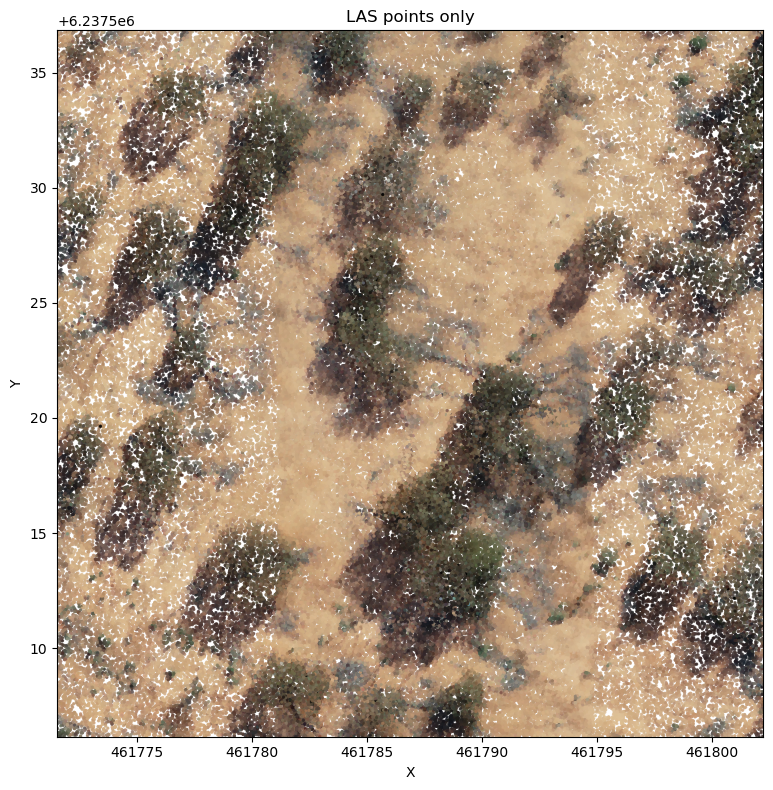

In [31]:
# --- View LAS only (coloured by RGB if available; else by Z) ---
import laspy, numpy as np, matplotlib.pyplot as plt
import rasterio

# Get extent from raster
with rasterio.open(A_TILE) as src:
    extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

las_path = OUT_DIR / f"{A_TILE.stem}.las"
if not las_path.exists():
    las_path = sample_out
las = laspy.read(las_path)

x = las.x
y = las.y
use_rgb = hasattr(las, 'red') and hasattr(las, 'green') and hasattr(las, 'blue')
if use_rgb:
    r = np.asarray(las.red, dtype=np.float32)
    g = np.asarray(las.green, dtype=np.float32)
    b = np.asarray(las.blue, dtype=np.float32)
    colors = np.stack([r, g, b], axis=-1) / 65535.0
else:
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    colors = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

n = len(x); max_pts = 200000
if n > max_pts:
    idx = np.random.choice(n, size=max_pts, replace=False)
    x = x[idx]; y = y[idx]
    colors = colors[idx]

plt.figure(figsize=(8, 8))
plt.title('LAS points only')
plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
if use_rgb:
    plt.scatter(x, y, s=2, c=colors, alpha=0.8)
else:
    plt.scatter(x, y, s=2, c=colors, cmap='viridis', alpha=0.8)
plt.tight_layout(); plt.show()

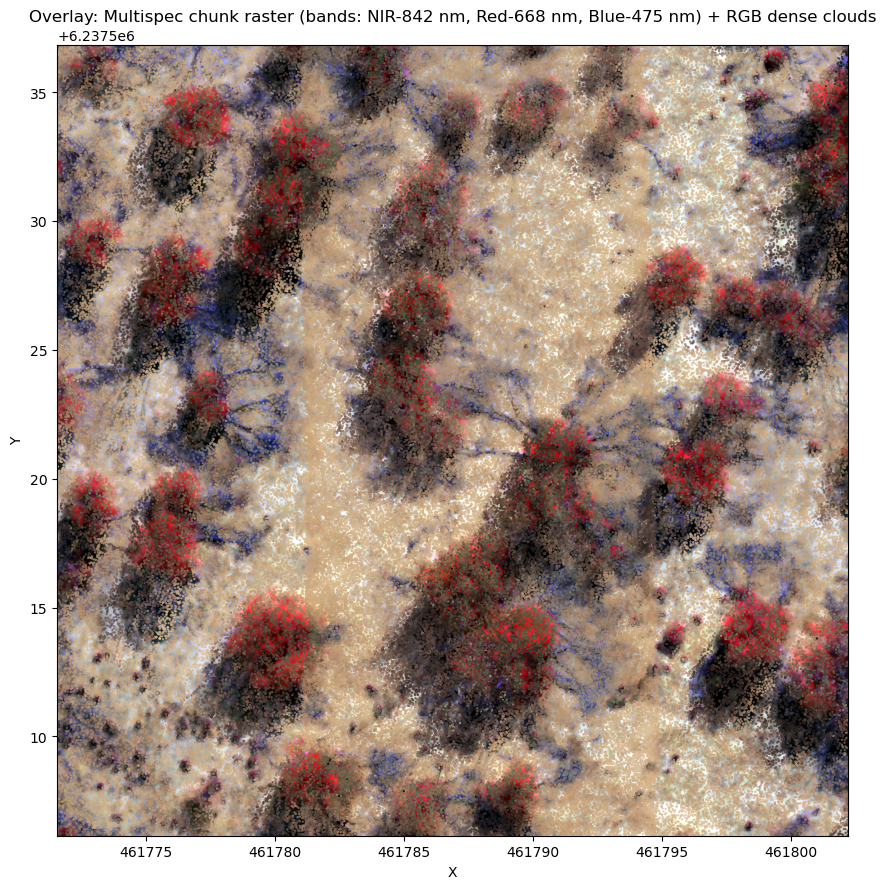

In [34]:
# --- Overlay: Raster 5/3/1 + LAS ---
import matplotlib.pyplot as plt
import rasterio

# Get extent from raster if not already in scope
try:
    extent
    rgb
except NameError:
    import numpy as np
    with rasterio.open(A_TILE) as src:
        if src.count < 5:
            raise RuntimeError(f"Raster has {src.count} bands; need >= 5 for 5/3/1 RGB.")
        b5 = src.read(5).astype(np.float32)
        b3 = src.read(3).astype(np.float32)
        b1 = src.read(1).astype(np.float32)
        def norm_band(b):
            lo, hi = np.percentile(b[np.isfinite(b)], [2, 98])
            b = np.clip((b - lo) / (hi - lo + 1e-6), 0, 1)
            b[~np.isfinite(b)] = 0
            return b
        rgb = np.stack([norm_band(b5), norm_band(b3), norm_band(b1)], axis=-1)
        extent = (src.bounds.left, src.bounds.right, src.bounds.bottom, src.bounds.top)

plt.figure(figsize=(9, 9))
plt.imshow(rgb, extent=extent, origin='upper')
plt.xlabel('X'); plt.ylabel('Y')
plt.xlim(extent[0], extent[1])
plt.ylim(extent[2], extent[3])
plt.gca().set_aspect('equal')
plt.title('Overlay: Multispec chunk raster (bands: NIR-842 nm, Red-668 nm, Blue-475 nm) + RGB dense clouds')
try:
    cvals = colors
except NameError:
    # compute simple Z colors if colors not in scope
    import numpy as np, laspy
    las = laspy.read(OUT_DIR / f"{A_TILE.stem}.las")
    x = las.x; y = las.y
    z = np.asarray(las.z, dtype=np.float32)
    z_lo, z_hi = np.percentile(z, [2, 98])
    cvals = np.clip((z - z_lo) / (z_hi - z_lo + 1e-6), 0, 1)

if cvals.ndim == 2:
    plt.scatter(x, y, s=0.5, c=cvals, alpha=0.7)
else:
    plt.scatter(x, y, s=0.5, c=cvals, cmap='viridis', alpha=0.7)
plt.tight_layout(); plt.show()